# Part 2.1 and 2.2: Data Preparation and LoRA Fine-Tuning

This notebook runs the same way on **Kaggle**, **Colab** and **RunPod**.

| Step | Kaggle | Colab | RunPod |
|---|---|---|---|
| GPU | Settings → Accelerator → GPU T4 x2 (only GPU 0 is used) | Runtime → Change runtime type → T4 GPU | Pick a 16 GB card |
| Internet | Settings → Internet → On | On by default | On by default |
| Secrets | Add-ons → Secrets: `HF_TOKEN` (write), `GITHUB_TOKEN` (read) | Key icon in the left bar: `HF_TOKEN`, `GITHUB_TOKEN`, notebook access on | Pod env vars `HF_TOKEN`, `GITHUB_TOKEN` |
| Long run | Save Version → Save & Run All (Commit) | Run all, keep the tab open | Run All, keep the pod running |

Outputs: processed train/test splits on a private Hugging Face dataset, two LoRA adapters on Hugging Face, and a training table.

In [1]:
import os, subprocess, sys
STAMP = "e4e3528"
REPO = "github.com/patel-manav20/Data266-Lab2-Team17.git"
REF = "member_pramod"
ON_KAGGLE = os.path.exists("/kaggle/working")
ON_COLAB = os.path.isdir("/content") and not ON_KAGGLE
WORK ="/kaggle/working" if ON_KAGGLE else "/workspace" if os.path.isdir("/workspace") else os.path.abspath(".")
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

def secret(name):
    if os.environ.get(name):
        return os.environ[name]
    try:
        if ON_KAGGLE:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(name)
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None

if subprocess.run(["git", "rev-parse"], capture_output=True).returncode:
    dst = f"{WORK}/repo"
    if not os.path.isdir(dst) and secret("GITHUB_TOKEN"):
        subprocess.run(["git", "clone", "-q", f"https://{secret('GITHUB_TOKEN')}@{REPO}", dst], check=True)
        subprocess.run(["git", "-C", dst, "checkout", "-q", REF], check=True)
    if os.path.isdir(dst):
        os.chdir(dst)

import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip() or STAMP
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': 'e4e3528', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'gpu': 'Tesla T4', 'seed': 266}


In [2]:
%pip install -q diffusers peft datasets imagehash tensorboard accelerate
%pip uninstall -y -q torchao
import importlib.metadata as md
print({p: md.version(p) for p in ["torch", "diffusers", "transformers", "accelerate", "peft", "datasets", "huggingface_hub", "imagehash"]})

{'torch': '2.14.1+cu130', 'diffusers': '0.42.1', 'transformers': '5.22.1', 'accelerate': '1.15.0', 'peft': '0.21.2', 'datasets': '4.8.5', 'huggingface_hub': '1.33.0', 'imagehash': '4.3.2'}


## Settings

In [5]:
DATASET = "reach-vb/pokemon-blip-captions"
BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
RES = 512
STEPS = 1500
BATCH = 1
GRAD_ACCUM = 4
LR = 1e-4
RUNS = {"lora_r4": 4, "lora_r32": 32}
TAG = DATASET.split("/")[-1].split("-")[0]
if ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    KEEP = "/content/drive/MyDrive/data266_p2"
else:
    KEEP = WORK
ROOT = subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True, text=True).stdout.strip()
OUT = f"{KEEP}/outputs" if ON_COLAB or not ROOT else f"{ROOT}/part2_diffusion/member_pramod/outputs"
RUNS_DIR = f"{KEEP}/runs"
DATA = f"{WORK}/p2_data"
os.makedirs(OUT, exist_ok=True)

from huggingface_hub import HfApi, login
api, HF_USER = None, None
if secret("HF_TOKEN"):
    login(token=secret("HF_TOKEN"))
    api = HfApi()
    HF_USER = api.whoami()["name"]
print(HF_USER, TAG, OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pramodsatyad pokemon /content/drive/MyDrive/data266_p2/outputs


## 2.1 Data preparation

An image is **corrupted** if it fails to decode, is smaller than 64 px, or has an empty caption.
An image is a **duplicate** if its pixels match an earlier image exactly, or its perceptual hash (pHash) matches one.

In [6]:
import io, json, hashlib, collections, shutil, imagehash, pandas as pd
from datasets import load_dataset, Image as HFImage
from PIL import Image

raw = load_dataset(DATASET, split="train").cast_column("image", HFImage(decode=False))
records, md5s, phashes = [], set(), set()
removed = collections.Counter()
for i, r in enumerate(raw):
    try:
        b = r["image"]["bytes"] or open(r["image"]["path"], "rb").read()
        Image.open(io.BytesIO(b)).verify()
        img = Image.open(io.BytesIO(b)).convert("RGB")
        if min(img.size) < 64 or not r["text"].strip():
            raise ValueError
    except Exception:
        removed["corrupted"] += 1
        continue
    md5, ph = hashlib.md5(img.tobytes()).hexdigest(), str(imagehash.phash(img))
    if md5 in md5s:
        removed["exact_duplicate"] += 1
        continue
    if ph in phashes:
        removed["near_duplicate"] += 1
        continue
    md5s.add(md5); phashes.add(ph)
    records.append({"src_idx": i, "text": r["text"].strip(), "img": img})

data_summary = {"dataset": DATASET, "loaded": len(raw), "kept": len(records), **{k: removed[k] for k in ["corrupted", "exact_duplicate", "near_duplicate"]}}
if len(records) < 500:
    raise ValueError("The cleaned dataset must contain at least 500 images.")
print(data_summary)

README.md:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/731 [00:00<?, ?B/s]

data/train-00000-of-00001-566cc9b19d7203(…): reconstructing file:   0%|          |  0.00B / 99.7MB            

data/train-00000-of-00001-566cc9b19d7203(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/833 [00:00<?, ? examples/s]

{'dataset': 'reach-vb/pokemon-blip-captions', 'loaded': 833, 'kept': 832, 'corrupted': 0, 'exact_duplicate': 0, 'near_duplicate': 1}


Split 90% train / 10% test with seed 266, then resize the short side to 512 and center-crop to 512×512.

In [7]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(records))
n_test = round(0.1 * len(records))
split_idx = {"test": sorted(perm[:n_test].tolist()), "train": sorted(perm[n_test:].tolist())}

def to_res(img):
    s = RES / min(img.size)
    img = img.resize((round(img.width * s), round(img.height * s)), Image.BICUBIC)
    l, t = (img.width - RES) // 2, (img.height - RES) // 2
    return img.crop((l, t, l + RES, t + RES))

for split, ids in split_idx.items():
    d = f"{DATA}/{split}"
    os.makedirs(d, exist_ok=True)
    expected = {f"{records[k]['src_idx']:05d}.png" for k in ids}
    for name in os.listdir(d):
        if name.endswith(".png") and name not in expected:
            os.remove(f"{d}/{name}")
    with open(f"{d}/metadata.jsonl", "w") as f:
        for k in ids:
            name = f"{records[k]['src_idx']:05d}.png"
            to_res(records[k]["img"]).save(f"{d}/{name}")
            f.write(json.dumps({"file_name": name, "text": records[k]["text"]}) + "\n")

test_caps = [{"file_name": f"{records[k]['src_idx']:05d}.png", "text": records[k]["text"]} for k in split_idx["test"]]
with open(f"{OUT}/p2_test_captions.json", "w") as f:
    json.dump(test_caps, f, indent=1)
data_summary.update({s: len(v) for s, v in split_idx.items()})
data_summary.update(seed=SEED, resolution=RES)
with open(f"{OUT}/p2_data_summary.json", "w") as f:
    json.dump(data_summary, f, indent=1)
if KEEP != WORK:
    for split in split_idx:
        target = f"{KEEP}/p2_data/{split}"
        if os.path.isdir(target):
            shutil.rmtree(target)
        shutil.copytree(f"{DATA}/{split}", target)
print(data_summary)

{'dataset': 'reach-vb/pokemon-blip-captions', 'loaded': 833, 'kept': 832, 'corrupted': 0, 'exact_duplicate': 0, 'near_duplicate': 1, 'test': 83, 'train': 749, 'seed': 266, 'resolution': 512}


### Dataset description

In [8]:
sizes = collections.Counter(f"{r['img'].width}x{r['img'].height}" for r in records)
lens = pd.Series([len(r["text"].split()) for r in records])
words = collections.Counter(w for r in records for w in r["text"].lower().split() if len(w) > 3)
colors = ["red", "blue", "green", "yellow", "pink", "purple", "orange", "black", "white", "brown", "gray", "grey"]
color_counts = {c: sum(c in r["text"].lower().split() for r in records) for c in colors}
print("original sizes:", dict(sizes.most_common(5)))
print("caption words: mean %.1f, min %d, max %d" % (lens.mean(), lens.min(), lens.max()))
print("top words:", words.most_common(20))
print("colour mentions:", dict(sorted(color_counts.items(), key=lambda x: -x[1])))
print("captions starting with 'a cartoon':", sum(r["text"].lower().startswith("a cartoon") for r in records))

original sizes: {'1280x1280': 453, '431x431': 257, '1080x1080': 27, '272x272': 12, '937x937': 4}
caption words: mean 9.3, min 6, max 16
top words: [('with', 530), ('cartoon', 335), ('drawing', 312), ('character', 250), ('blue', 170), ('white', 151), ('pokemon', 146), ('eyes', 120), ('yellow', 120), ('green', 99), ('bird', 92), ('pink', 88), ('black', 86), ('head', 65), ('animal', 62), ('flying', 56), ('looking', 56), ('very', 55), ('cute', 55), ('through', 49)]
colour mentions: {'blue': 169, 'white': 149, 'yellow': 116, 'green': 97, 'black': 85, 'pink': 82, 'red': 81, 'purple': 39, 'orange': 19, 'brown': 16, 'gray': 14, 'grey': 2}
captions starting with 'a cartoon': 191


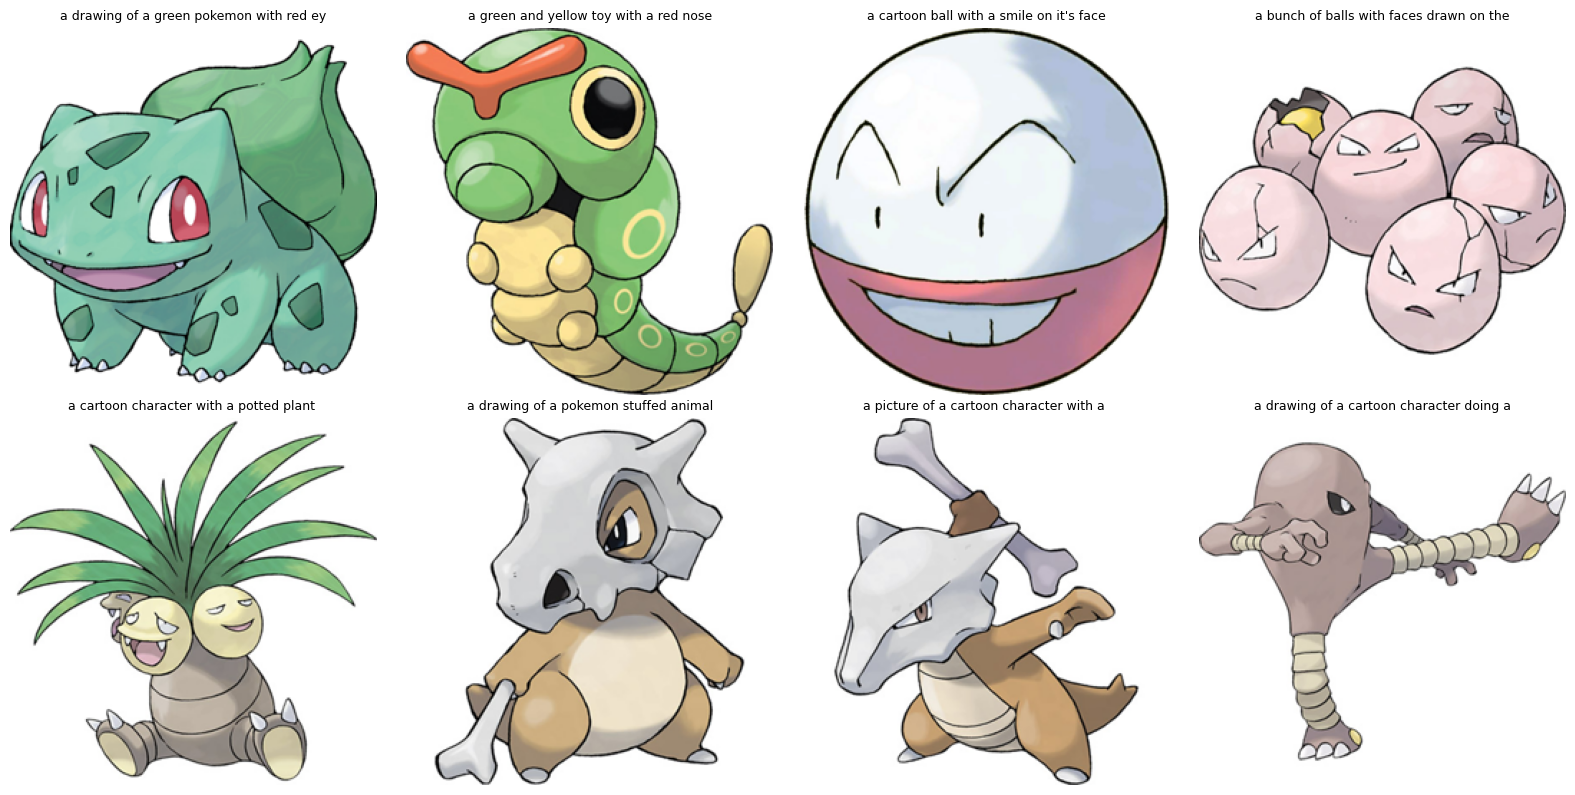

In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, k in zip(axes.flat, split_idx["train"][:8]):
    ax.imshow(to_res(records[k]["img"]).resize((256, 256))); ax.axis("off")
    ax.set_title(records[k]["text"][:40], fontsize=9)
plt.tight_layout(); plt.show()

Push the processed splits to a private Hugging Face dataset so the generation and evaluation notebook, and Part 3, use the exact same test images.

In [10]:
DATA_REPO = f"{HF_USER}/data266-p2-{TAG}-splits"
if api:
    api.create_repo(DATA_REPO, repo_type="dataset", private=True, exist_ok=True)
    api.upload_folder(folder_path=DATA, repo_id=DATA_REPO, repo_type="dataset")
    print(f"https://huggingface.co/datasets/{DATA_REPO}")
else:
    print("no HF_TOKEN: splits kept in", DATA)

No files have been modified since last commit. Skipping to prevent empty commit.


https://huggingface.co/datasets/pramodsatyad/data266-p2-pokemon-splits


## 2.2 Fine-tuning

Both runs use the diffusers example script `train_text_to_image_lora.py` (same version as the installed diffusers), the same data, the same 1500 optimizer steps and the same settings. The only difference is the LoRA rank (4 vs 32).
Peak total GPU memory is sampled from `nvidia-smi` every 2 s while training runs.
Checkpoints are saved every 250 steps (on Colab they go to Google Drive). Training time is written to disk every minute. If a session dies, run all cells again: training resumes from the last checkpoint and the time adds to the total.

In [11]:
import threading, time, urllib.request
from safetensors.torch import load_file

SCRIPT = f"{WORK}/train_text_to_image_lora.py"
import diffusers
DIFFUSERS_TAG = "v" + diffusers.__version__.split(".dev")[0]
urllib.request.urlretrieve(f"https://raw.githubusercontent.com/huggingface/diffusers/{DIFFUSERS_TAG}/examples/text_to_image/train_text_to_image_lora.py", SCRIPT)
print("training script from diffusers", DIFFUSERS_TAG)

def gpu_mem_mb():
    q = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits", "-i", "0"], capture_output=True, text=True)
    return int(q.stdout.split()[0])

def last_progress(log):
    tail = open(log, "rb").read()[-4000:].decode(errors="ignore").replace("\r", "\n").splitlines()
    return next((l.strip() for l in reversed(tail) if "Steps:" in l), "")

def train(name, rank):
    out = f"{RUNS_DIR}/{name}"
    os.makedirs(out, exist_ok=True)
    timing_file = f"{out}/timing.json"
    weights = f"{out}/pytorch_lora_weights.safetensors"
    if os.path.exists(weights) and not os.path.exists(timing_file):
        raise RuntimeError(f"{name}: weights exist but timing.json is missing; restore the measured training log before reporting results.")
    timing = {"seconds": 0, "peak_mb": 0}
    if os.path.exists(timing_file):
        with open(timing_file) as f:
            timing = json.load(f)
    if not os.path.exists(f"{out}/pytorch_lora_weights.safetensors"):
        cmd = ["accelerate", "launch", "--num_processes=1", "--mixed_precision=fp16", SCRIPT,
               f"--pretrained_model_name_or_path={BASE_MODEL}", f"--train_data_dir={DATA}/train",
               "--image_column=image", "--caption_column=text", f"--resolution={RES}", "--random_flip",
               f"--train_batch_size={BATCH}", f"--gradient_accumulation_steps={GRAD_ACCUM}", "--gradient_checkpointing",
               f"--max_train_steps={STEPS}", f"--learning_rate={LR}", "--lr_scheduler=cosine", "--lr_warmup_steps=0",
               f"--rank={rank}", f"--seed={SEED}", f"--output_dir={out}", "--checkpointing_steps=250",
               "--checkpoints_total_limit=2", "--resume_from_checkpoint=latest", "--dataloader_num_workers=2", "--mixed_precision=fp16"]
        peak, done = [gpu_mem_mb()], threading.Event()
        log = f"{out}/train.log"
        t0 = time.time()
        def save_timing():
            with open(timing_file + ".tmp", "w") as f:
                json.dump({"seconds": timing["seconds"] + time.time() - t0, "peak_mb": max(timing["peak_mb"], peak[0])}, f)
            os.replace(timing_file + ".tmp", timing_file)
        def watch():
            last_print = last_save = time.time()
            while not done.is_set():
                peak[0] = max(peak[0], gpu_mem_mb())
                if time.time() - last_save > 60:
                    save_timing(); last_save = time.time()
                if time.time() - last_print > 300:
                    print(name, last_progress(log), flush=True); last_print = time.time()
                done.wait(2)
        with open(log, "a") as f:
            th = threading.Thread(target=watch, daemon=True); th.start()
            try:
                p = subprocess.run(cmd, stdout=f, stderr=subprocess.STDOUT)
            finally:
                done.set(); th.join()
                save_timing()
        with open(timing_file) as f:
            timing = json.load(f)
        if p.returncode:
            print("".join(open(log).readlines()[-40:]))
            raise RuntimeError(f"{name} failed")
    params = sum(v.numel() for v in load_file(f"{out}/pytorch_lora_weights.safetensors").values())
    return {"run": name, "method": f"LoRA rank {rank}", "trainable_params": params, "learning_rate": LR,
            "steps": STEPS, "batch_size": BATCH, "grad_accum": GRAD_ACCUM, "effective_batch": BATCH * GRAD_ACCUM,
            "peak_gpu_mem_gb": round(timing["peak_mb"] / 1024, 2), "train_minutes": round(timing["seconds"] / 60, 1),
            "gpu_hours": round(timing["seconds"] / 3600, 3), "gpu": torch.cuda.get_device_name(0)}

rows = []
os.makedirs(f"{KEEP}/adapters", exist_ok=True)
for name, rank in RUNS.items():
    rows.append(train(name, rank))
    shutil.copy(f"{RUNS_DIR}/{name}/pytorch_lora_weights.safetensors", f"{KEEP}/adapters/{name}.safetensors")
    pd.DataFrame(rows).to_csv(f"{OUT}/p2_training_runs.csv", index=False)
    if os.path.abspath(OUT) != os.path.abspath(f"{KEEP}/outputs"):
        os.makedirs(f"{KEEP}/outputs", exist_ok=True)
        shutil.copy(f"{OUT}/p2_training_runs.csv", f"{KEEP}/outputs/p2_training_runs.csv")
    print(rows[-1], flush=True)
runs_df = pd.DataFrame(rows)
runs_df.to_csv(f"{OUT}/p2_training_runs.csv", index=False)
runs_df

training script from diffusers v0.42.1
lora_r4 Steps:  91%|█████████ | 1360/1500 [42:26<04:17,  1.84s/it, lr=2.13e-6, step_loss=0.0049]
{'run': 'lora_r4', 'method': 'LoRA rank 4', 'trainable_params': 797184, 'learning_rate': 0.0001, 'steps': 1500, 'batch_size': 1, 'grad_accum': 4, 'effective_batch': 4, 'peak_gpu_mem_gb': 4.26, 'train_minutes': 53.8, 'gpu_hours': 0.897, 'gpu': 'Tesla T4'}
lora_r32 Steps:  95%|█████████▍| 1420/1500 [44:14<02:25,  1.82s/it, lr=7e-7, step_loss=0.00484]
{'run': 'lora_r32', 'method': 'LoRA rank 32', 'trainable_params': 6377472, 'learning_rate': 0.0001, 'steps': 1500, 'batch_size': 1, 'grad_accum': 4, 'effective_batch': 4, 'peak_gpu_mem_gb': 4.35, 'train_minutes': 47.8, 'gpu_hours': 0.797, 'gpu': 'Tesla T4'}


,run,method,trainable_params,learning_rate,steps,batch_size,grad_accum,effective_batch,peak_gpu_mem_gb,train_minutes,gpu_hours,gpu
0,lora_r4,LoRA rank 4,797184,0.0001,1500,1,4,4,4.26,53.8,0.897,Tesla T4
1,lora_r32,LoRA rank 32,6377472,0.0001,1500,1,4,4,4.35,47.8,0.797,Tesla T4


## Save both LoRA adapters and push them to Hugging Face

In [12]:
import shutil
links = {}
os.makedirs(f"{KEEP}/adapters", exist_ok=True)
for name in RUNS:
    shutil.copy(f"{RUNS_DIR}/{name}/pytorch_lora_weights.safetensors", f"{KEEP}/adapters/{name}.safetensors")
    if not api:
        continue
    repo_id = f"{HF_USER}/data266-p2-{TAG}-{name}"
    api.create_repo(repo_id, exist_ok=True)
    api.upload_file(path_or_fileobj=f"{RUNS_DIR}/{name}/pytorch_lora_weights.safetensors",
                    path_in_repo="pytorch_lora_weights.safetensors", repo_id=repo_id)
    links[name] = f"https://huggingface.co/{repo_id}"
if api:
    links["splits"] = f"https://huggingface.co/datasets/{DATA_REPO}"
json.dump(links, open(f"{OUT}/p2_hf_links.json", "w"), indent=1)
links

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._lora_weights.safetensors:  17%|#7        |  555kB / 3.23MB            

Validating                    :           |   0%            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._lora_weights.safetensors:   2%|2         |  555kB / 25.5MB            

Validating                    :           |   0%            

{'lora_r4': 'https://huggingface.co/pramodsatyad/data266-p2-pokemon-lora_r4',
 'lora_r32': 'https://huggingface.co/pramodsatyad/data266-p2-pokemon-lora_r32',
 'splits': 'https://huggingface.co/datasets/pramodsatyad/data266-p2-pokemon-splits'}